# Peso degli ordini k — plot

Legge i file prodotti da `notebooks/data_generation/weight_of_orders.ipynb`
(`results/contributo_ordini/{res}_digits/{C_TYPE}/{ALGO}/contributo_ordini_{res}_digits_alpha_{tag}.parquet`).

- ordine 0 = intrinsic complexity (Δ)
- ordini k ≥ 1 = input complexity

Gli α disponibili vengono letti dai nomi dei file: aggiungendo file i plot si aggiornano da soli.
Le figure sono salvate in PDF (per LaTeX) e PNG in `results/contributo_ordini/plots/{C_TYPE}/{ALGO}/`.
Stile e palette sono definiti in `src/plotting.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)
from src.plotting import load_stability, check_eta0, plot_stability, plot_corr_vs_order

set_style()
import re

## Configurazione

In [2]:
C_TYPE = "C_classica"                        # "C_classica" | "C_nilpotente"
ALGO   = "extended_fitness_no_imports"       # "extended_fitness_no_imports" | "extended_eci_no_imports"
RESOLUTIONS = [4, 6]
ALPHA_REF = 1.0                              # alpha del plot 1

RESULTS = ROOT / "results" / "contributo_ordini"
SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "contributo_ordini" / C_TYPE / ALGO

## Caricamento

In [3]:
ALPHA_RE = re.compile(r"alpha_(\d+)_(\d+)\.parquet$")

def load_pesi(res, c_type=C_TYPE, algo=ALGO):
    """Dict {alpha: pesi_df} per una risoluzione, ordinato per alpha."""
    folder = RESULTS / f"{res}_digits" / c_type / algo
    out = {}
    for f in folder.glob(f"contributo_ordini_{res}_digits_alpha_*.parquet"):
        m = ALPHA_RE.search(f.name)
        if m:
            out[float(f"{m.group(1)}.{m.group(2)}")] = pd.read_parquet(f)
    if not out:
        raise FileNotFoundError(f"Nessun file in {folder}")
    return dict(sorted(out.items()))

pesi = {res: load_pesi(res) for res in RESOLUTIONS}
for res, d in pesi.items():
    print(f"{res} digits -> alpha disponibili: {list(d)}")

4 digits -> alpha disponibili: [0.001, 0.01, 0.1, 1.0]
6 digits -> alpha disponibili: [0.001, 0.01, 0.1, 1.0]


## Plot 1 — w(k) a α = 1, 4 vs 6 digits

Se ci fosse invarianza di risoluzione le due curve coinciderebbero.

4 digits: w(0) = 0.0282   (valore da citare in didascalia)
6 digits: w(0) = 0.0105   (valore da citare in didascalia)


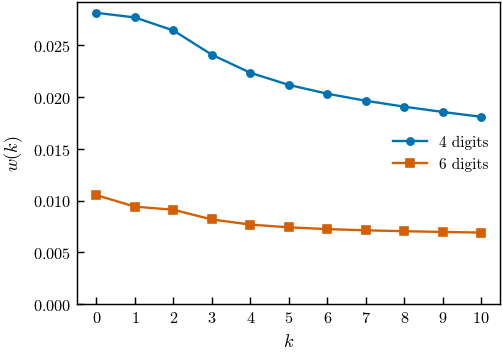

In [4]:
def plot_wk_resolutions(pesi, alpha=ALPHA_REF):
    fig, ax = plt.subplots(figsize=figsize(*SINGLE))
    for res, d in pesi.items():
        if alpha not in d:
            print(f"alpha={alpha} mancante per {res} digits"); continue
        df = d[alpha]
        ax.plot(df["ordine"], df["peso_medio"], ls="none", marker=RES_MARKER[res],   # k discreto: solo marker
                color=PALETTE[res], label=f"{res} digits")
        print(f"{res} digits: w(0) = {df['peso_medio'].iloc[0]:.4f}   (valore da citare in didascalia)")
    ax.set_xlabel(r"$k$")
    ax.set_ylabel(r"$w(k)$")
    ax.set_xticks(df["ordine"])
    ax.set_ylim(bottom=0)
    ax.legend(loc="center right")
    fig.tight_layout()
    if SAVE_FIGS:
        tag = f"{alpha:.3f}".replace(".", "_")
        save_fig(fig, FIG_DIR / f"wk_4vs6_digits_alpha_{tag}")
    plt.show()

plot_wk_resolutions(pesi)

## Plot 2 — w(k) per diversi α

Una figura per risoluzione (da affiancare in LaTeX), stesso asse y. Scala log sulle y: al variare di α i pesi coprono molti ordini di grandezza.

4 digits


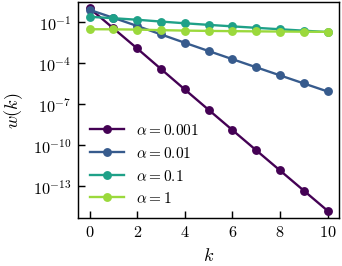

6 digits


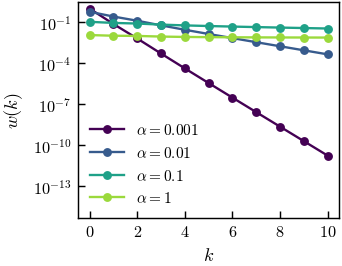

In [5]:
def plot_wk_alphas(pesi, logy=True):
    all_dfs = [df for d in pesi.values() for df in d.values()]
    ylim = common_ylim(all_dfs, ["peso_medio"]) if not logy else (
        0.3 * min(df["peso_medio"].min() for df in all_dfs),
        3.0 * max(df["peso_medio"].max() for df in all_dfs))
    for res, d in pesi.items():
        fig, ax = plt.subplots(figsize=figsize(*HALF))
        alphas = list(d)
        log_a = np.log10(alphas)
        norm = (log_a - log_a.min()) / (np.ptp(log_a) or 1)   # colore ~ log(alpha)
        for a, t in zip(alphas, norm):
            df = d[a]
            ax.plot(df["ordine"], df["peso_medio"], ls="none", marker="o", color=SEQ_CMAP(t),   # k discreto
                    label=rf"$\alpha = {a:g}$")
        ax.set_xlabel(r"$k$")
        ax.set_ylabel(r"$w(k)$")
        ax.set_xticks(df["ordine"][::2])
        if logy:
            ax.set_yscale("log")
        ax.set_ylim(*ylim)
        ax.legend(loc="lower left")
        fig.tight_layout()
        if SAVE_FIGS:
            save_fig(fig, FIG_DIR / f"wk_vs_alpha_{res}_digits")
        print(f"{res} digits"); plt.show()

plot_wk_alphas(pesi)

## Plot 3 — peso totale intrinsic vs input al variare di a = ρα

- intrinsic = w(0)
- input = 1 − w(0)

Usa la scansione fitta in a (sezione "SCAN IN a" di `data_generation/weight_of_orders.ipynb`,
file `scan_a_{res}_digits.parquet`), con la stessa griglia di a per le due risoluzioni.
La linea verticale tratteggiata segna a = 1; il notebook stampa anche il punto a* in cui
le due curve si incrociano (w(0) = 1/2), ottenuto interpolando in log a.

L'input **non** è calcolato come Σ_{k=1}^{K-1} w(k): con K = 11 la serie è troncata.

In [6]:
def load_scan(res, c_type=C_TYPE, algo=ALGO):
    f = RESULTS / f"{res}_digits" / c_type / algo / f"scan_a_{res}_digits.parquet"
    scan = pd.read_parquet(f)
    tot = scan[scan["ordine"] == 0][["a", "alpha", "rho", "peso_medio"]].rename(columns={"peso_medio": "intrinsic"})
    tot["input"] = 1 - tot["intrinsic"]
    return tot.sort_values("a").reset_index(drop=True)

def crossing(tot):
    """a* in cui w(0) = 1/2, interpolando linearmente in log a."""
    d = tot["intrinsic"].to_numpy() - 0.5
    i = np.where(np.sign(d[:-1]) != np.sign(d[1:]))[0]
    if len(i) == 0:
        return np.nan
    i = i[0]
    la = np.log10(tot["a"].to_numpy())
    return 10 ** (la[i] - d[i] * (la[i + 1] - la[i]) / (d[i + 1] - d[i]))

scans = {res: load_scan(res) for res in RESOLUTIONS}
for res, tot in scans.items():
    print(f"{res} digits: rho = {tot['rho'].iloc[0]:.2f},  incrocio a* = {crossing(tot):.3f},  "
          f"w(0) ad a = 1: {np.interp(0, np.log10(tot['a']), tot['intrinsic']):.3f}")

4 digits: rho = 34.68,  incrocio a* = 1.017,  w(0) ad a = 1: 0.504
6 digits: rho = 94.39,  incrocio a* = 1.091,  w(0) ad a = 1: 0.522


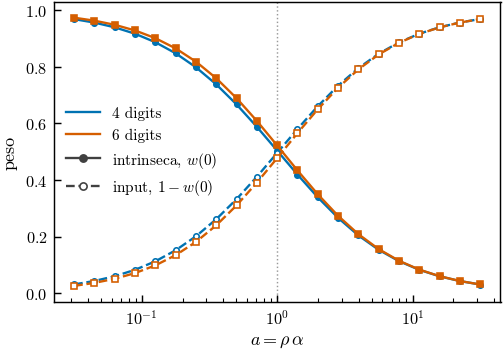

In [7]:
def plot_totali(scans):
    fig, ax = plt.subplots(figsize=figsize(*SINGLE))
    ax.axvline(1, color="0.6", lw=0.8, ls=":", zorder=0)
    for res, tot in scans.items():
        c = PALETTE[res]
        ax.plot(tot["a"], tot["intrinsic"], ls="-",  color=c)      # a continuo: solo linee
        ax.plot(tot["a"], tot["input"],     ls="--", color=c)
    ax.set_xscale("log")
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel(r"$a = \rho\,\alpha$")
    ax.set_ylabel(r"peso")
    two_part_legend(ax,
                    [(f"{r} digits", PALETTE[r]) for r in scans],
                    [(r"intrinseca, $w(0)$", "-", True), (r"input, $1 - w(0)$", "--", False)],
                    loc="center left")
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / "intrinsic_vs_input_vs_a")
    plt.show()

plot_totali(scans)